In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import json, glob, os, re
from matplotlib.ticker import LogLocator, LogFormatterSciNotation, NullFormatter
from matplotlib.ticker import AutoMinorLocator, FormatStrFormatter


def load_json(path):
    with open(path) as f:
        return json.load(f)
    
    
# --- Match the article's body font (Computer Modern Roman, 10 pt) ---
mpl.rcParams.update({
    "text.usetex":       True,
    "font.family":       "serif",
    "font.size":         10,
    "axes.labelsize":    10,
    "axes.titlesize":    10,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "lines.linewidth":   1.0,
    "axes.linewidth":    0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4,
    "ytick.minor.width": 0.4,
})
plt.rcParams["text.latex.preamble"] = r"\usepackage{amsmath}\usepackage{bm}"

C_TPM = "#0072B2"   
C_PB  = "#D55E00"

# Neon

In [2]:
Ne_dets = 6.69 * 10**6

Ne_real_eval = 128.709475548738
print("Neon true eval:")
print(Ne_real_eval)

Ne_HF = -128.49634973054026
Ne_HF_relerr = np.abs(np.abs(Ne_real_eval) - np.abs(Ne_HF)) / np.abs(Ne_real_eval)

# unsparsified results
Ne_bags_unsp = np.array([1, 961, 158051, 2953352])
Ne_eval_unsp = np.array([-128.49634973054026, -128.7003137474214,-128.70926699744766, -128.70947361734795])

Neon true eval:
128.709475548738


### Neon full matrix info

In [3]:
neon_l1 = -128.709475548731
neon_l2 = -127.976045354342
neon_ln = -75.120644927935
HF_weight = 0.964499 # square overlap

print("HF square overlap = ", HF_weight)

rel_eigengap = np.abs(np.abs(neon_l1) - np.abs(neon_l2))/np.abs(neon_l1)
print("relative eigengap = ", rel_eigengap)

opt_shift = 2 / (neon_l2 + neon_ln)
print("optimal shift = ", opt_shift)

neon_l1_shifted = 1-opt_shift * neon_l1
neon_l2_shifted = 1-opt_shift * neon_l2
rel_eigengap_opt_shift = np.abs(np.abs(neon_l1_shifted) - np.abs(neon_l2_shifted))/np.abs(neon_l1_shifted)
print("relative eigengap after optimal shift = ", rel_eigengap_opt_shift)

HF square overlap =  0.964499
relative eigengap =  0.005698338768471754
optimal shift =  -0.009847526304935201
relative eigengap after optimal shift =  0.02700293336038672


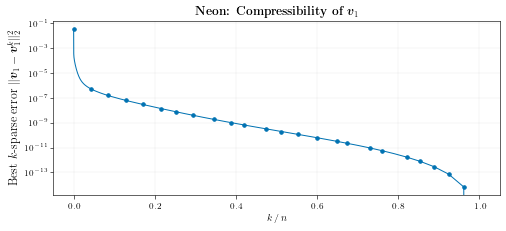

overlap 0.9: k = 1, k/n = 1.49e-07
overlap 0.99: k = 1, k/n = 1.49e-07
overlap 0.999: k = 1, k/n = 1.49e-07
overlap 0.9999: k = 89, k/n = 1.33e-05


In [46]:
# Neon: compressibility of the true FCI ground state.
COMP_JSON = "Neon/results/full_fci_neon_compressibility.json"
COMP_BIN  = "Neon/results/full_fci_neon_v1.bin"   # fallback if the JSON is absent
if os.path.exists(COMP_JSON):
    d      = load_json(COMP_JSON)
    ks     = np.asarray(d["k"], float)
    tau    = np.asarray(d["tail"], float) ** 2
    n_full = d["n"]
else:                                              # compute from the raw vector
    v = np.fromfile(COMP_BIN, dtype=np.float64)
    n_full = v.size
    a = np.sort(np.abs(v))[::-1]
    a /= np.linalg.norm(a)
    tail2 = np.concatenate([np.cumsum((a[::-1]) ** 2)[::-1], [0.0]])
    ks  = np.unique(np.round(np.logspace(0, np.log10(n_full), 400)).astype(int))
    tau = np.maximum(tail2[ks], 0.0)
    ks  = ks.astype(float)

x = ks / n_full

fig, ax = plt.subplots(figsize=(8, 3.2))

# Pick marker positions evenly spaced in LINEAR x (not evenly spaced in index,
# which is what you want for a loglog plot since log-spaced ks -> even index
# spacing = even spacing in log(x). Here x is linear, so we instead sample
# ~25 target x-locations directly and snap each to the nearest data index.)
n_markers = 25
x_targets = np.linspace(x[0], x[-1], n_markers)
marker_idx = np.unique(np.searchsorted(x, x_targets))
marker_idx = np.clip(marker_idx, 0, len(x) - 1)

ax.semilogy(x, tau, linestyle="-", color=C_TPM,
          label=r"$\|v - v_{[k]}\|_2$")
ax.semilogy(x[marker_idx], tau[marker_idx], linestyle="None",
          marker="o", markersize=3.5, color=C_TPM)

ax.set_title(r"\textbf{Neon: Compressibility of $\bm{v}_1$}", fontsize=12)
ax.set_xlabel(r"$k\,/\,n$")
ax.set_ylabel(r"Best $k$-sparse error $\|\bm{v}_1 - \bm{v}_1^{k}\|_2^{2}$", fontsize=12)
ax.grid(True, which="both", alpha=0.3, linewidth=0.4)
# leg = ax.legend(loc="lower left", frameon=True, framealpha=1.0, facecolor="white",
#                 edgecolor="0.7", fancybox=False, borderpad=0.5, labelspacing=0.4)
# leg.set_zorder(10)
# leg.get_frame().set_linewidth(0.6)
# minor_subs = np.arange(2, 10) * 0.1
# # for axis in (ax.yaxis):
# ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=15))
# ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=15))
# ax.yaxis.set_major_formatter(LogFormatterSciNotation(base=10.0))
# ax.yaxis.set_minor_formatter(NullFormatter())
fig.savefig("neon_compressibility.pdf", bbox_inches="tight")
plt.show()

for f in (0.9, 0.99, 0.999, 0.9999):
    k = ks[np.argmax(tau <= np.sqrt(1 - f ** 2))]
    print(f"overlap {f}: k = {k:.0f}, k/n = {k / n_full:.3g}")

### Neon TPM vs Greedy

In [4]:
# in my data, which ks converged tol=1e-11
PB_ks_converged = np.array([1000, 2000, 4000, 8000, 16000, 35000, 70000, 87500, 105000,
                            122500, 140000, 157500, 175000,
                            192500, 210000, 227500, 245000, 262500, 280000])

# in my data, which ks converged tol = 1e-11
TPM_ks_converged = np.array([1000, 2000, 4000, 8000, 16000, 35000, 70000, 87500, 105000,
                            122500, 140000, 157500, 175000,
                            192500, 210000, 227500, 245000, 262500, 280000])
PB_end_relerrs = []
TPM_end_relerrs = []

for k in TPM_ks_converged:
    PB_name = f"Neon/results/greedy/greedy_k{k}.json"
    TPM_name = f"Neon/results/tpm/tpm_k{k}.json"

    with open(PB_name, "r") as f:
        data_PB = json.load(f)
    with open(TPM_name, "r") as f:
        data_TPM = json.load(f)

    PB_bags = np.array(data_PB["bagsizes"])
    PB_relerrs = np.array(data_PB["rel_errors"])

    TPM_bags = np.array(data_TPM["bagsizes"])
    TPM_relerrs = np.array(data_TPM["rel_errors"])
    
    PB_end_relerrs.append(PB_relerrs[-1])
    TPM_end_relerrs.append(TPM_relerrs[-1])

In [4]:
16000 / Ne_dets

0.002391629297458894

3.419086979414023e-07
3.8187669988990633e-07


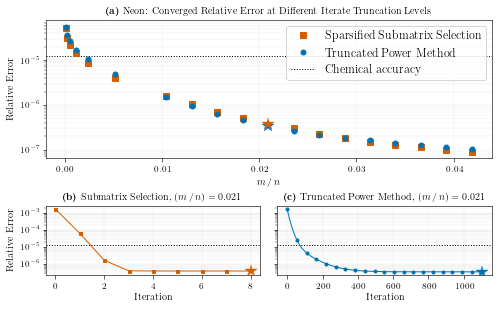

In [9]:
# Colorblind-safe palette
C_TPM = "#0072B2"   
C_PB  = "#D55E00"   

# Shared style for the highlight stars (kept out of the legend)
star_kw = dict(marker="*", markersize=13, linestyle="none",
               markeredgewidth=0.4, zorder=5, label="_nolegend_")

# ---- Load bottom-panel data --------------------------------------------------
k        = 140_000
idx_star = int(np.where(TPM_ks_converged == k)[0][0])
fraction = k / Ne_dets

with open(f"Neon/results/greedy/greedy_k{k}.json") as f:
    data_PB  = json.load(f)
with open(f"Neon/results/tpm/tpm_k{k}.json") as f:
    data_TPM = json.load(f)

PB_relerrs = np.array(data_PB["rel_errors"])
TPM_relerrs = np.array(data_TPM["rel_errors"])

TPM_end_relerrs = np.asarray(TPM_end_relerrs)
PB_end_relerrs  = np.asarray(PB_end_relerrs)
PB_relerrs  = np.insert(PB_relerrs,  0, Ne_HF_relerr)
TPM_relerrs = np.insert(TPM_relerrs, 0, Ne_HF_relerr)


x               = np.asarray(TPM_ks_converged) / Ne_dets   

# ---- x-arrays ---------------------------------------------------------------
x  = TPM_ks_converged / Ne_dets          # (a)
x1 = np.arange(len(PB_relerrs[:10]))     # (b)
x2 = np.arange(len(TPM_relerrs))         # (c)

# ---- Layout: top single panel; bottom two panels share y --------------------
fig     = plt.figure(figsize=(8, 4))
subfigs = fig.subfigures(2, 1, height_ratios=[1, 0.5], hspace=0.1)
ax0 = subfigs[0].subplots()
ax1, ax2_plt = subfigs[1].subplots(1, 2, sharey=True,
                                   gridspec_kw={"wspace": 0.08})

# ---- (a) Scatter; star at idx_star ------------------------------------------
mask = np.ones_like(x, dtype=bool)
mask[idx_star] = False
ax0.semilogy(x[mask], PB_end_relerrs[mask],  "s", color=C_PB,
             label="Sparsified Submatrix Selection",      markersize=5.5)
ax0.semilogy(x[mask], TPM_end_relerrs[mask], "o", color=C_TPM,
             label="Truncated Power Method", markersize=5)

ax0.plot(x[idx_star], TPM_end_relerrs[idx_star], color=C_TPM, **star_kw)
ax0.plot(x[idx_star], PB_end_relerrs[idx_star],  color=C_PB,  **star_kw)
print(TPM_end_relerrs[idx_star])
print(PB_end_relerrs[idx_star])
ax0.set_title(r"\textbf{(a)} Neon: Converged Relative Error at Different "
              r"Iterate Truncation Levels")
ax0.set_xlabel(r"$m\,/\,n$")
ax0.set_ylabel("Relative Error")
ax0.grid(True, which="both", alpha=0.3, linewidth=0.4)

# --- Chemical accuracy line (relative error) ---------------------------------
KCAL_PER_HA = 627.509
Ne_Etot     = 128.7                      # |E_tot| in Ha (atom: E_nuc=0, so elec=tot)
chem_relerr = (1.0 / KCAL_PER_HA) / Ne_Etot   # = 1 kcal/mol / |E|  ≈ 1.24e-5

lbl = "Chemical accuracy"
ax0.axhline(chem_relerr, color="black", linestyle=":", linewidth=1.0,
           zorder=1, label=lbl)
ax1.axhline(chem_relerr, color="black", linestyle=":", linewidth=1.0,
           zorder=1, label=lbl)
ax2_plt.axhline(chem_relerr, color="black", linestyle=":", linewidth=1.0,
           zorder=1, label=lbl)


ax0.legend(frameon=True, loc="upper right", fontsize=12,
           facecolor="white", edgecolor="0.8", framealpha=0.8)
# ax0.legend(frameon=False, loc="best")

# ---- (b) Sparsified greedy: star replaces the final marker ------------------
ax1.semilogy(x1, PB_relerrs[:10], "s-", color=C_PB, markersize=3,
             markevery=list(range(len(x1) - 1)))
ax1.plot(x1[-1], PB_relerrs[:10][-1], color=C_PB, **star_kw)
ax1.set_title(r"\textbf{(b)} Submatrix Selection, $(m\,/\,n) = 0.021$")
ax1.set_xlabel(r"Iteration")
ax1.set_ylabel("Relative Error")
ax1.grid(True, which="both", alpha=0.3, linewidth=0.4)

# ---- (c) TPM: thinned markers, star on final iterate ------------------------
step      = max(1, len(x2) // 20)
markers_c = list(range(0, len(x2) - 1, step))
ax2_plt.semilogy(x2, TPM_relerrs, "o-", color=C_TPM,
                 markersize=3, markevery=markers_c)
ax2_plt.plot(x2[-1], TPM_relerrs[-1], color=C_TPM, **star_kw)
ax2_plt.set_title(r"\textbf{(c)} Truncated Power Method, $(m\,/\,n) = 0.021$")
ax2_plt.set_xlabel(r"Iteration")
plt.setp(ax2_plt.get_yticklabels(), visible=False)
ax2_plt.grid(True, which="both", alpha=0.3, linewidth=0.4)

# ---- Major + minor ticks/grid on every decade for all three panels ----------
minor_subs = np.arange(2, 10) * 0.1
for ax in (ax0, ax1, ax2_plt):
    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=15))
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=15))
    ax.yaxis.set_major_formatter(LogFormatterSciNotation(base=10.0))
    ax.yaxis.set_minor_formatter(NullFormatter())

fig.savefig("neon_combined.pdf", bbox_inches="tight")
plt.show()

### Neon TPM vs Greedy with optimal shift

# Ozone Results

Using the CAS(18e, 87o), `gsno_om` orbitals

### Benchmarking the true ground state energy ($E_{\text{FCI}}$)

Linear extrapolation of $y = E_{\text{var}} + E_{\text{PT2}}$ against $p = \lvert E_{\text{PT2}} \rvert$, fit on the five points below and evaluated at $p \to 0$. All runs use $N_{\text{cdets}}/N_{\text{tdets}} = 0.05$.

**Benchmark points**

| N<sub>cdets</sub> | N<sub>tdets</sub> | E<sub>var</sub>&nbsp;(Ha) | &#124;E<sub>PT2</sub>&#124;&nbsp;(mHa) | y&nbsp;(Ha) | PT2 |
|---:|---:|---:|---:|---:|:---|
| 10&nbsp;000 | 200&nbsp;000 | &minus;293.1076991245 | 68.698 | &minus;293.1763973976 | exact |
| 25&nbsp;000 | 500&nbsp;000 | &minus;293.1221680202 | 55.059 | &minus;293.1772268558 | exact |
| 50&nbsp;000 | 1&nbsp;000&nbsp;000 | &minus;293.1314681034 | 46.422 | &minus;293.1778903002 | ε<sub>2</sub>&nbsp;=&nbsp;2×10<sup>&minus;4</sup> |
| 100&nbsp;000 | 2&nbsp;000&nbsp;000 | &minus;293.1398865046 | 38.608 | &minus;293.1784944469 | ε<sub>2</sub>&nbsp;=&nbsp;2×10<sup>&minus;4</sup> |
| 150&nbsp;000 | 3&nbsp;000&nbsp;000 | &minus;293.1444233969 | 34.395 | &minus;293.1788184644 | ε<sub>2</sub>&nbsp;=&nbsp;2×10<sup>&minus;4</sup> |

Chemical accuracy $= 1.594$ mHa (1 kcal/mol).

FCI energy extrapolation with SHCI: https://pubs.aip.org/aip/jcp/article/147/16/164111/76673/Excited-states-using-semistochastic-heat-bath

FCI energy extrapolation with ASCI: https://pubs.acs.org/jctcce/article/17/7/4092/495042/Near-Exact-CASSCF-Level-Geometry-Optimization-with

E_REF = -225.1395553889 Ha  (electronic -293.1812248405)
sigma(E_REF) = 0.1207 mHa   s = 0.0660 mHa   R^2 = 0.99658
slope b = 0.071127


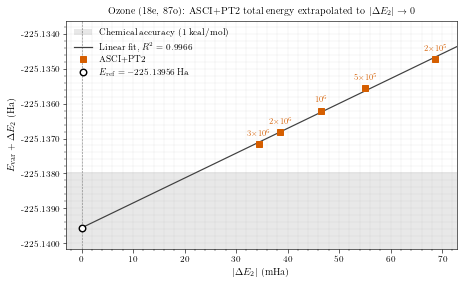

In [10]:
# =============================================================================
# Ozone (18e, 87o), gsno_om orbitals.
# Linear extrapolation of the ASCI+PT2 total energy to |Delta E_2| -> 0.
# =============================================================================

C_FIT  = "#D55E00"   # orange -- benchmark series (colorblind-safe)
C_LINE = "0.25"      # neutral grey for the regression line

# ---- Data -------------------------------------------------------------------
E_NUC = 68.0416694516        # Ha. Matrix elements are electronic only.

# Benchmark series.  N_cdets/N_tdets = 0.05, eps2 = 2e-7.
PT = np.array([68.6982731, 55.0588356, 46.4221968, 38.6079423, 34.3950675])
E  = np.array([-293.1763973977, -293.1772268558, -293.1778903002,
               -293.1784944469, -293.1788184644]) + E_NUC
LAB = [r"$2{\times}10^{5}$", r"$5{\times}10^{5}$", r"$10^{6}$",
       r"$2{\times}10^{6}$", r"$3{\times}10^{6}$"]

CHEM_ACC = 1.5936            # mHa == 1 kcal/mol

# ---- Fit --------------------------------------------------------------------
n = len(PT)
slope, E_REF = np.polyfit(PT, E, 1)          # E_REF = intercept at |dE2| = 0
resid = E - (E_REF + slope * PT)
s_res = np.sqrt((resid ** 2).sum() / (n - 2))
Sxx   = ((PT - PT.mean()) ** 2).sum()
sig_a = s_res * np.sqrt(1.0 / n + PT.mean() ** 2 / Sxx)
R2    = 1.0 - (resid ** 2).sum() / ((E - E.mean()) ** 2).sum()

print(f"E_REF = {E_REF:.10f} Ha  (electronic {E_REF - E_NUC:.10f})")
print(f"sigma(E_REF) = {sig_a*1e3:.4f} mHa   s = {s_res*1e3:.4f} mHa   R^2 = {R2:.5f}")
print(f"slope b = {slope*1000:.6f}")

# ---- Figure -----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4.2))

XMIN, XMAX = -3.0, 1.06 * PT.max()
x_line = np.linspace(0.0, XMAX, 200)

ax.axhspan(E_REF - CHEM_ACC * 1e-3, E_REF + CHEM_ACC * 1e-3,
           color="black", alpha=0.09, zorder=0, linewidth=0,
           label="Chemical accuracy (1 kcal/mol)")
ax.axvline(0.0, color="gray", linestyle="--", linewidth=0.6, zorder=1)

ax.plot(x_line, E_REF + slope * x_line, "-", color=C_LINE, linewidth=1.2,
        zorder=2, label=rf"Linear fit, $R^2 = {R2:.4f}$")
ax.plot(PT, E, "s", color=C_FIT, markersize=5.5, zorder=4,
        label="ASCI+PT2")
ax.plot(0.0, E_REF, "o", color="black", markersize=6.5, zorder=6,
        markerfacecolor="white", markeredgewidth=1.4,
        label=rf"$E_{{\rm ref}} = {E_REF:.5f}$ Ha")

for p, e, lab in zip(PT, E, LAB):
    ax.annotate(lab, (p, e), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=8, color=C_FIT)

ax.set_title(r"Ozone (18e, 87o): ASCI+PT2 total energy extrapolated to "
             r"$|\Delta E_2| \to 0$")
ax.set_xlabel(r"$|\Delta E_2|$ (mHa)")
ax.set_ylabel(r"$E_{\rm var} + \Delta E_2$ (Ha)")
ax.set_xlim(XMIN, XMAX)
ax.set_ylim(E_REF - 0.6e-3, E.max() + 1.1e-3)
ax.ticklabel_format(axis="y", useOffset=False, style="plain")
ax.yaxis.set_major_formatter(FormatStrFormatter("%.4f"))
ax.grid(True, which="both", alpha=0.3, linewidth=0.4)
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())
ax.legend(frameon=False, loc="upper left", fontsize=9)

fig.savefig("ozone_extrapolation.pdf", bbox_inches="tight")
plt.show()

# ---- Downstream helpers -----------------------------------------------------
def err(E_total):
    """Absolute error (Ha) against the extrapolated benchmark."""
    return np.abs(E_total - E_REF)

def rel_err(E_total):
    """Relative error against the extrapolated benchmark."""
    return np.abs(E_total - E_REF) / np.abs(E_REF)

### TPM vs Sparsified Selected Submatrix Method vs ASCI + PT2 

**Parameters**:
* TPM was run with $m = 10^6$
* sparsified Selected Submatrix Method was run with $m = 10^6$
* ASCI was run with $n_{cdets} = 10^6$ and $n_{tdets} = 2\times 10^7$
* PT2 was run with $\gamma = 10^{-7}$

Truncated Power Method ($m = 10^6$)
-224.80000715307503
Sparsified Submatrix Selection ($m = 10^6$)
-225.0866304081347


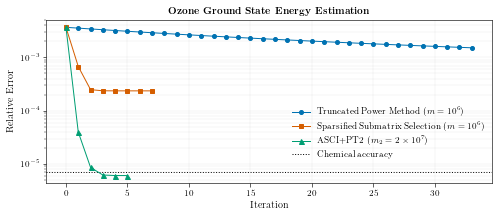

In [11]:
# ============================ USER INPUT ============================
# Constants added to every run's energy trajectory (Ha).
# From the get_ozone_inputs output:  E_HF (electronic) + E_NUC = total HF.
E_HF  = -292.3591666356      # electronic Hartree-Fock energy
E_NUC =   68.041669451557    # nuclear repulsion

# Reference TOTAL energy for the relative error  |E - E_REF| / |E_REF|  (Ha).
E_REF = E_REF                    # <-- set to your benchmark / FCI total energy

# One JSON per run. Each stores a per-iteration ENERGY list under one of the
# keys in ENERGY_KEYS; E_HF + E_NUC are added to turn it into a total energy.
# Style per run:  (legend label, path, color, marker)
RUNS = [
    (r"Truncated Power Method ($m = 10^6$)",         "./ozone_new_inputs/results/tpm/O3_tpm_m1M_ooc.json",    "#0072B2", "o"),
    (r"Sparsified Submatrix Selection ($m = 10^6$)", "./ozone_new_inputs/results/greedy/O3_greedy_m1M_ooc.json", "#D55E00", "s")
#     (r"ASCI ($nnz(x_k) = 2\times 10^7$)",                 "./ozone_new_inputs/results/asci/O3_asci_c1M_t20M.json", "#009E73", "^"),
]

ASCI_PT2 = -293.1797565879 + E_NUC # |S| = 20 million, PT2 done with eps2 = 1.5e7

# Prepend the HF point (E_HF + E_NUC) as iteration 0.  False to skip.
HF_START = True

OUTFILE = "ozone_plot.pdf"
USE_TEX = True                  # requires a LaTeX install; False for plain text
# ====================================================================

ENERGY_KEYS = ("eigval_history", "energies", "energy", "E", "E_var", "variational_energies")


def load_total_energy(path):
    with open(path) as f:
        d = json.load(f)
    for k in ENERGY_KEYS:
        if k in d:
            return np.asarray(d[k], float) + E_NUC
    raise KeyError(f"{path}: none of {ENERGY_KEYS} found.")


def rel_err(E_total):
    if E_REF is None:
        raise ValueError("Set E_REF (benchmark total energy) in USER INPUT.")
    return np.abs(np.abs(E_total) - np.abs(E_REF)) / abs(E_REF)


plt.rcParams["text.usetex"] = USE_TEX
bold = (lambda s: r"\textbf{" + s + "}") if USE_TEX else (lambda s: s)

# Highlight star on each final iterate (kept out of the legend).
star_kw = dict(marker="*", markersize=13, linestyle="none",
               markeredgewidth=0.4, zorder=5, label="_nolegend_")

E_HF_TOT = E_HF + E_NUC
fig, ax = plt.subplots(figsize=(8, 3))

for label, path, color, marker in RUNS:
    E_total = load_total_energy(path)
    if HF_START:
        E_total = np.insert(E_total, 0, E_HF_TOT)   # iteration 0 = HF
    y = rel_err(E_total)
    x = np.arange(len(y))
    step = max(1, len(x) // 25)                      # thin markers on long runs
    mev = list(range(0, len(x), step))
    ax.semilogy(x, y, marker=marker, linestyle="-", color=color,
                markersize=4, markevery=mev, label=label)
    print(label)
    print(E_total[-1])
#     ax.plot(x[-1], y[-1], color=color, **star_kw)

# --- ASCI+PT2 trajectory ----------------------------------------------------
C_ASCI = "#009E73"
with open("./ozone_new_inputs/results/asci/O3_asci_pt2_c1M_t20M.json") as f:
    d_ap = json.load(f)

E_var_ap = np.asarray(d_ap["E_var"],          float) + E_NUC
E_tot_ap = np.asarray(d_ap["E_var_plus_PT2"], float) + E_NUC
if HF_START:
    E_var_ap = np.insert(E_var_ap, 0, E_HF_TOT)
    E_tot_ap = np.insert(E_tot_ap, 0, E_HF_TOT)
x_ap = np.arange(len(E_var_ap))

# ax.semilogy(x_ap, rel_err(E_var_ap), marker="^", linestyle="--", color=C_ASCI,
#             markersize=4, alpha=0.55,
#             label=r"ASCI ($nnz(x_k) = 2\times 10^7$)")
ax.semilogy(x_ap, rel_err(E_tot_ap), marker="^", linestyle="-", color=C_ASCI,
            markersize=5,
            label=r"ASCI+PT2 ($m_2 = 2\times 10^7$)")
# ----------------------------------------------------------------------------

# --- Chemical accuracy line (relative error) --------------------------------
KCAL_PER_HA = 627.509
chem_relerr = (1.0 / KCAL_PER_HA) / abs(E_REF)      # 7.078e-06 for ozone

ax.axhline(chem_relerr, color="black", linestyle=":", linewidth=1.0,
           zorder=1, label="Chemical accuracy")
# ----------------------------------------------------------------------------

ax.set_title(bold("Ozone Ground State Energy Estimation"))
ax.set_xlabel(r"Iteration")
ax.set_ylabel("Relative Error")
ax.grid(True, which="both", alpha=0.3, linewidth=0.4)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 0.1))

minor_subs = np.arange(2, 10) * 0.1
ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=15))
ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=minor_subs, numticks=15))
ax.yaxis.set_major_formatter(LogFormatterSciNotation(base=10.0))
ax.yaxis.set_minor_formatter(NullFormatter())

fig.savefig(OUTFILE, bbox_inches="tight")
plt.show()